# ML Lab 9 — FBG tilt prediction
Md Minha Uddin · 2401CS39

In [1]:
from pathlib import Path
from collections import Counter
import json, time
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, RBF
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
ROOT = Path.cwd()
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
SOURCE = ROOT / "FBG biaxial tilt sensor.xlsx"
SEED = 42
FEATURES = {"F1": ["d1", "d2"], "F2": ["diff"], "F3": ["avg"], "F4": ["diff", "avg"]}
if not SOURCE.exists():
    from google.colab import files
    files.upload()
assert SOURCE.exists()

## Task 1 — Dataset check
Row 1 is a reading. I used only the two experimental sheets.

In [2]:
def load_data(sheet):
    df = pd.read_excel(SOURCE, sheet_name=sheet, header=None, usecols='A:G').dropna(how='all')
    df.columns = ['angle', 'fbg1', 'fbg2', 'd1', 'd2', 'given_diff', 'given_avg']
    df = df.apply(pd.to_numeric, errors='raise')
    assert len(df) == 37 and df.notna().all().all()
    df['diff'] = df.d1 - df.d2
    df['avg'] = (df.d1 + df.d2) / 2
    assert np.allclose(df['diff'], df.given_diff, atol=1e-06)
    assert np.allclose(df['avg'], df.given_avg, atol=1e-06)
    return df.reset_index(drop=True)

data = {"axial": load_data("Experiment axial "), "transverse": load_data("Experiment transverse ")}
for axis, df in data.items():
    print(axis, "rows:", len(df), "missing:", df.isna().sum().sum(), "duplicates:", df.duplicated().sum())
    stats = df.describe().T.rename(columns={"50%": "median"})
    stats["variance"] = df.var(numeric_only=True)
    display(stats[["mean", "median", "std", "variance", "min", "max"]])
    display(df.angle.value_counts().sort_index().rename("repeats").to_frame().T)

axial rows: 37 missing: 0 duplicates: 2


,mean,median,std,variance,min,max
angle,0.000000,0.000000e+00,52.121653,2716.666667,-90.000,90.000
fbg1,1535.215108,1.535216e+03,0.024458,0.000598,1535.178,1535.248
fbg2,1547.350378,1.547349e+03,0.024231,0.000587,1547.314,1547.385
d1,-0.891892,0.000000e+00,24.458336,598.210210,-38.000,32.000
d2,-0.621622,-2.000000e+00,24.230779,587.130631,-37.000,34.000
given_diff,-0.270270,2.273737e-10,48.666466,2368.424925,-71.000,68.000
given_avg,-0.756757,-5.000000e-01,0.751125,0.564189,-3.000,0.500
diff,-0.270270,0.000000e+00,48.666466,2368.424925,-71.000,68.000
avg,-0.756757,-5.000000e-01,0.751125,0.564189,-3.000,0.500


angle,-90,-80,-70,-60,-50,-40,-30,-20,-10,0,10,20,30,40,50,60,70,80,90
repeats,1,2,2,2,2,2,2,2,2,3,2,2,2,2,2,2,2,2,1


transverse rows: 37 missing: 0 duplicates: 0


,mean,median,std,variance,min,max
angle,0.000000,0.0,52.121653,2716.666667,-90.0,90.0
fbg1,435.000000,439.0,111.712926,12479.777778,251.0,583.0
fbg2,560.675676,566.0,105.520154,11134.503003,391.0,700.0
d1,174.000000,178.0,111.712926,12479.777778,-10.0,322.0
d2,156.675676,162.0,105.520154,11134.503003,-13.0,296.0
given_diff,17.324324,17.0,7.487226,56.058559,0.0,30.0
given_avg,165.337838,170.0,108.596159,11793.125751,-11.5,309.0
diff,17.324324,17.0,7.487226,56.058559,0.0,30.0
avg,165.337838,170.0,108.596159,11793.125751,-11.5,309.0


angle,-90,-80,-70,-60,-50,-40,-30,-20,-10,0,10,20,30,40,50,60,70,80,90
repeats,1,2,2,2,2,2,2,2,2,3,2,2,2,2,2,2,2,2,1


## Task 2 — Plots and scaling
The plots show sensor response, correlation, outliers and raw versus scaled inputs.

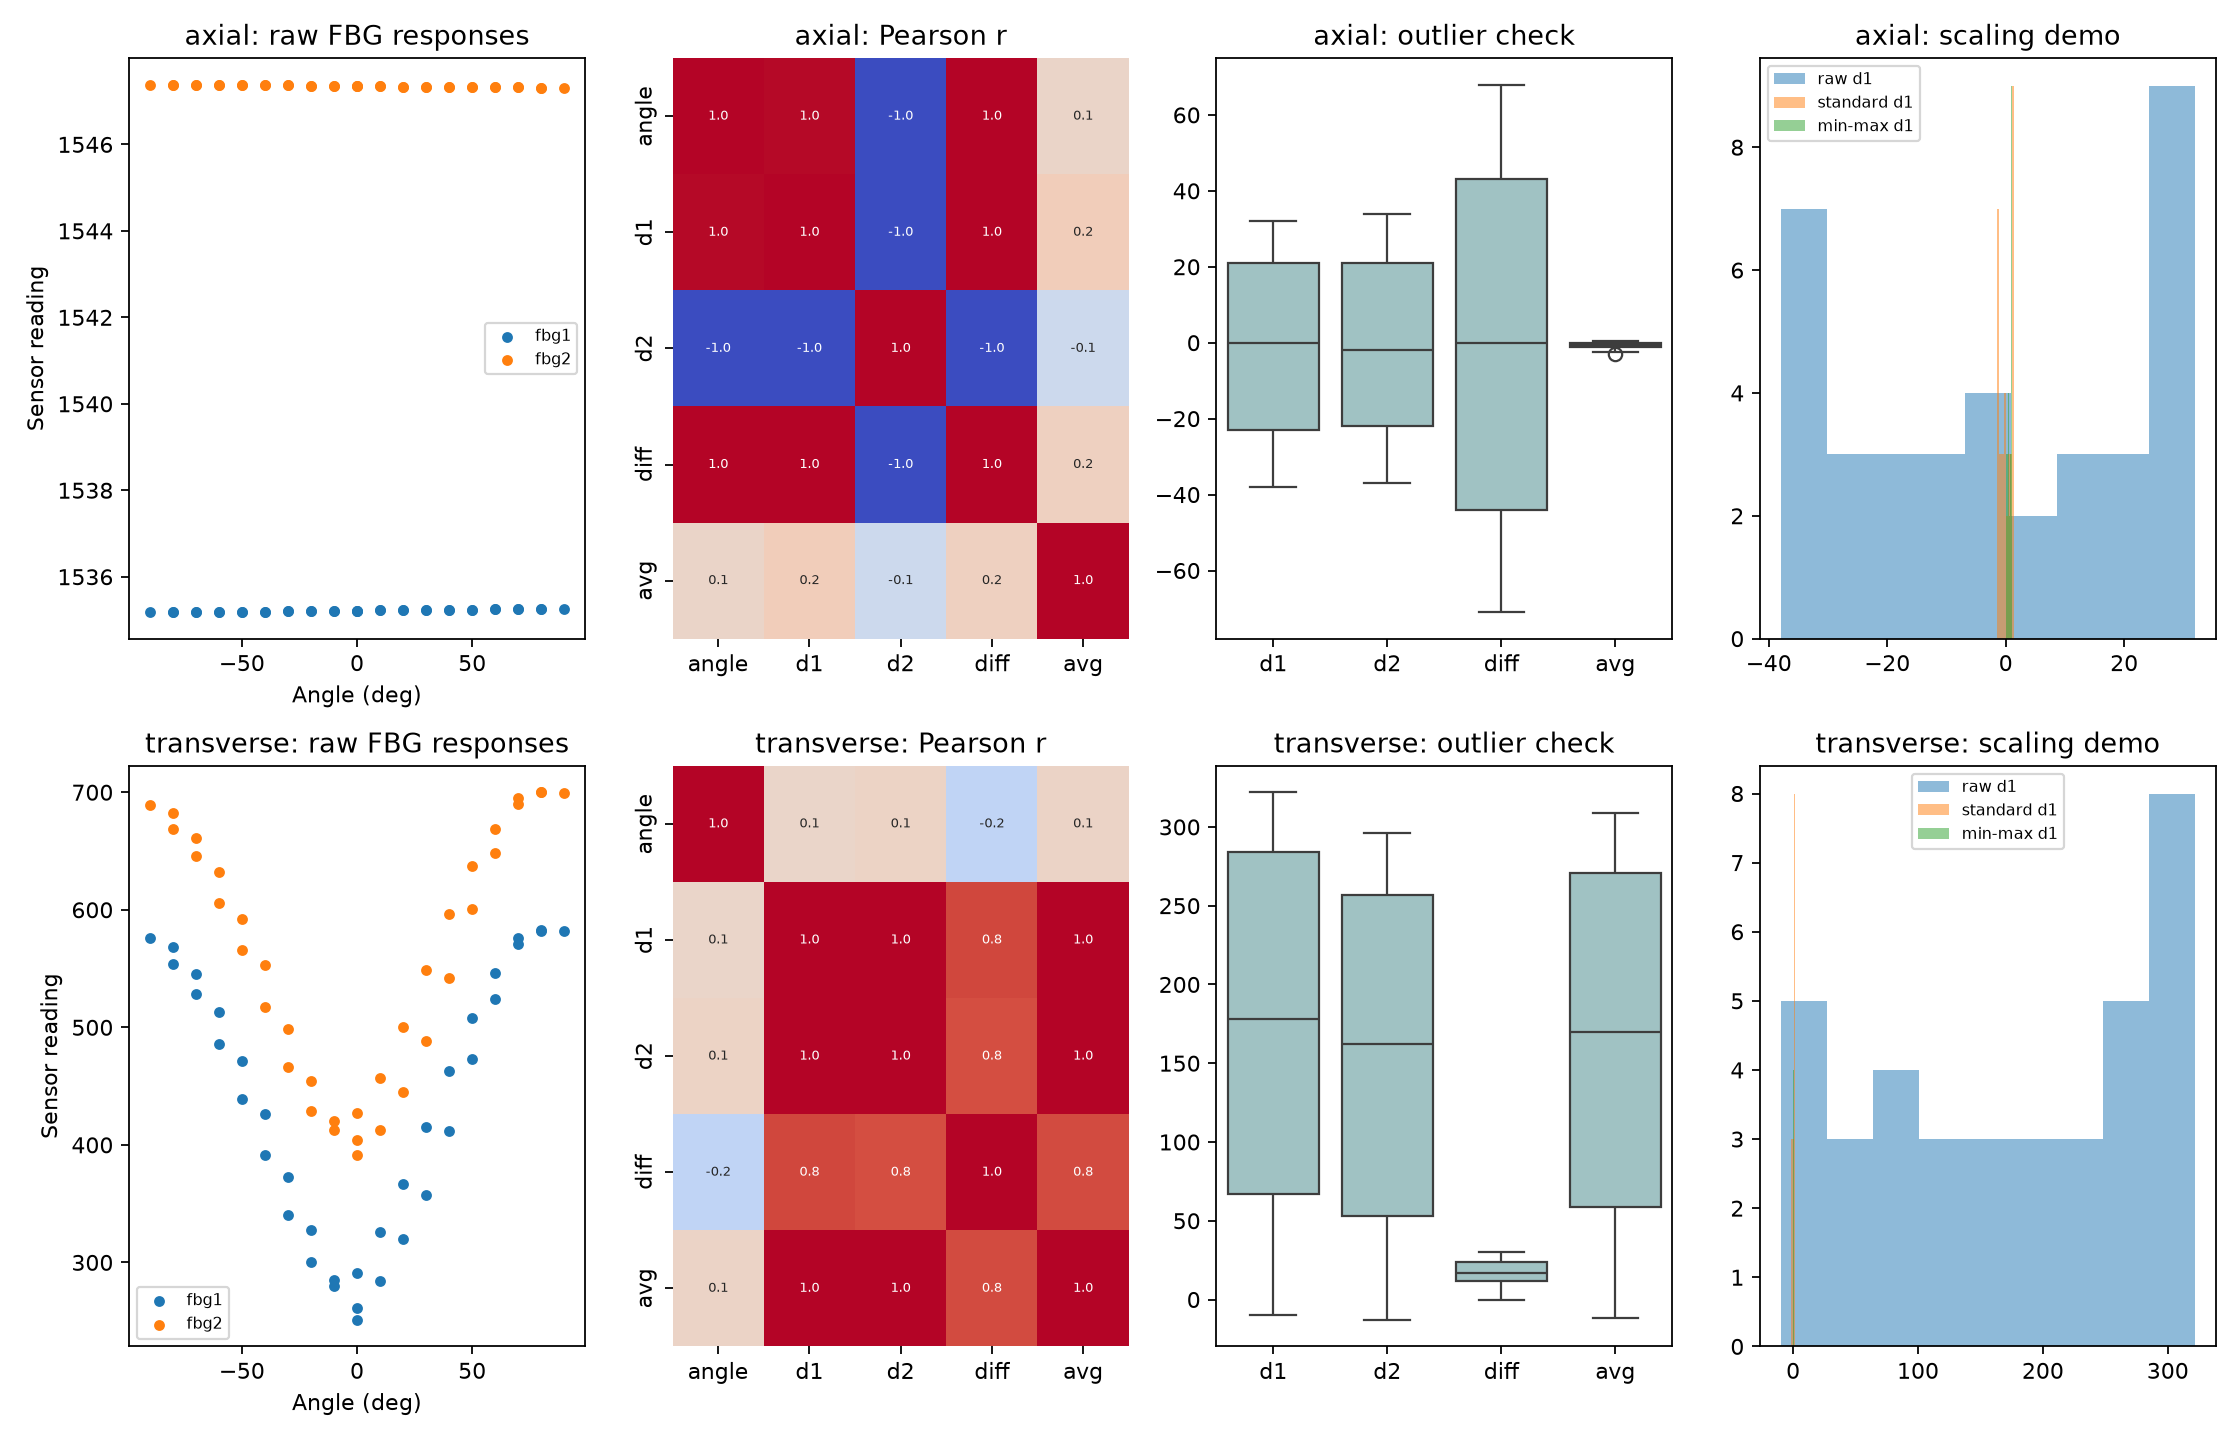

In [3]:
def plot_exploration(data):
    fig, axes = plt.subplots(2, 4, figsize=(14, 9))
    for i, (axis, df) in enumerate(data.items()):
        ax = axes[i]
        for c in ('fbg1', 'fbg2'):
            ax[0].scatter(df.angle, df[c], s=15, label=c)
        ax[0].set(title=f'{axis}: raw FBG responses', xlabel='Angle (deg)', ylabel='Sensor reading')
        ax[0].legend(fontsize=7)
        sns.heatmap(df[['angle', 'd1', 'd2', 'diff', 'avg']].corr(), vmin=-1, vmax=1, cmap='coolwarm', ax=ax[1], cbar=False, annot=True, fmt='.1f', annot_kws={'size': 6})
        ax[1].set_title(f'{axis}: Pearson r')
        sns.boxplot(data=df[['d1', 'd2', 'diff', 'avg']], ax=ax[2], color='#9ac7c9')
        ax[2].set_title(f'{axis}: outlier check')
        z = StandardScaler().fit_transform(df[['d1', 'd2']])
        mm = MinMaxScaler().fit_transform(df[['d1', 'd2']])
        ax[3].hist(df.d1, bins=9, alpha=0.5, label='raw d1')
        ax[3].hist(z[:, 0], bins=9, alpha=0.5, label='standard d1')
        ax[3].hist(mm[:, 0], bins=9, alpha=0.5, label='min-max d1')
        ax[3].set_title(f'{axis}: scaling demo')
        ax[3].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(OUT / 'exploration.png', dpi=160)
    plt.close(fig)

plot_exploration(data)
display(Image(filename=str(OUT / "exploration.png")))

## Task 3 — Features
F1 is both changes, F2 the difference, F3 the average and F4 both engineered values.

In [4]:
def model_pipe(estimator):
    return Pipeline([('scale', StandardScaler()), ('model', clone(estimator))])

def exploratory(df, axis):
    desc = df.describe().T.rename(columns={'50%': 'median'})
    desc['variance'] = df.var(numeric_only=True)
    desc.to_csv(OUT / f'{axis}_descriptive.csv')
    summary = {'observations': len(df), 'input_features': 2, 'missing_cells': int(df.isna().sum().sum()), 'duplicate_rows': int(df.duplicated(subset=['angle', 'fbg1', 'fbg2', 'd1', 'd2']).sum()), 'repeated_angles': {str(k): int(v) for k, v in df.angle.value_counts().items() if v > 1}, 'angle_min': float(df.angle.min()), 'angle_max': float(df.angle.max())}
    correlations = df[['d1', 'd2', 'diff', 'avg', 'angle']].corr()['angle']
    correlations.to_csv(OUT / f'{axis}_correlations.csv')
    comp = []
    for key, cols in FEATURES.items():
        pred = np.full(len(df), np.nan)
        for tr, te in GroupKFold(5).split(df, df.angle, df.angle):
            m = model_pipe(LinearRegression()).fit(df.iloc[tr][cols], df.angle.iloc[tr])
            pred[te] = m.predict(df.iloc[te][cols])
        comp.append({'axis': axis, 'feature': key, 'columns': '+'.join(cols), 'linear_grouped_RMSE': np.sqrt(mean_squared_error(df.angle, pred))})
    return (summary, pd.DataFrame(comp))

summaries, feature_tables = {}, []
for axis, df in data.items():
    summaries[axis], frame = exploratory(df, axis)
    feature_tables.append(frame)
feature_comparison = pd.concat(feature_tables, ignore_index=True)
feature_comparison.to_csv(OUT / "feature_comparison.csv", index=False)
display(feature_comparison)
for axis in data:
    display(pd.read_csv(OUT / f"{axis}_correlations.csv"))

,axis,feature,columns,linear_grouped_RMSE
0,axial,F1,d1+d2,6.684451
1,axial,F2,diff,6.174736
2,axial,F3,avg,55.419892
3,axial,F4,diff+avg,6.684451
4,transverse,F1,d1+d2,46.541561
5,transverse,F2,diff,53.889953
6,transverse,F3,avg,53.293019
7,transverse,F4,diff+avg,46.541561


,Unnamed: 0,angle
0,d1,0.991652
1,d2,-0.993927
2,diff,0.993246
3,avg,0.113524
4,angle,1.000000


,Unnamed: 0,angle
0,d1,0.108246
1,d2,0.128841
2,diff,-0.200728
3,avg,0.118272
4,angle,1.000000


## Task 4 — Statistical regression
Linear, polynomial and regularized models use the same grouped evaluation.

In [5]:
def specs():
    rows = [('SLR', None, LinearRegression(), ['F2', 'F3']), ('MLR', None, LinearRegression(), ['F1', 'F4'])]
    for degree in (2, 3):
        rows.append(('Polynomial', f'degree={degree}', Pipeline([('poly', PolynomialFeatures(degree, include_bias=False)), ('model', LinearRegression())]), list(FEATURES)))
    for alpha in (0.1, 1, 10):
        for name, cls in (('Ridge', Ridge), ('Lasso', Lasso)):
            rows.append((name, f'alpha={alpha}', cls(alpha=alpha, max_iter=20000), list(FEATURES)))
    for alpha in (0.1, 1):
        rows.append(('Elastic Net', f'alpha={alpha}, l1_ratio=0.5', ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=20000), list(FEATURES)))
    for kernel in ('linear', 'rbf'):
        rows.append(('SVR', f'kernel={kernel}, C=10, epsilon=0.1', SVR(kernel=kernel, C=10, epsilon=0.1), list(FEATURES)))
    for depth in (2, 3, 5):
        rows.append(('Decision Tree', f'max_depth={depth}', DecisionTreeRegressor(max_depth=depth, random_state=SEED), list(FEATURES)))
    for trees in (50, 100):
        rows.append(('Random Forest', f'n_estimators={trees}', RandomForestRegressor(n_estimators=trees, random_state=SEED, n_jobs=1), list(FEATURES)))
    for k in (3, 5, 7):
        rows.append(('KNN', f'n_neighbors={k}', KNeighborsRegressor(n_neighbors=k), list(FEATURES)))
    for lr in (0.01, 0.1):
        rows.append(('Gradient Boosting', f'learning_rate={lr}, n_estimators=100', GradientBoostingRegressor(learning_rate=lr, n_estimators=100, random_state=SEED), list(FEATURES)))
    for kernel, obj in (('RBF', RBF(1)), ('Matern', Matern(1.5, nu=1.5))):
        rows.append(('GPR', f'kernel={kernel}', GaussianProcessRegressor(kernel=obj, normalize_y=True, optimizer=None, alpha=0.01), list(FEATURES)))
    return rows

statistical = {"SLR", "MLR", "Polynomial", "Ridge", "Lasso", "Elastic Net"}
display(pd.DataFrame([(name, config or "default") for name, config, _, _ in specs() if name in statistical], columns=["Model", "Setting"]))

,Model,Setting
0,SLR,default
1,MLR,default
2,Polynomial,degree=2
3,Polynomial,degree=3
4,Ridge,alpha=0.1
5,Lasso,alpha=0.1
6,Ridge,alpha=1
7,Lasso,alpha=1
8,Ridge,alpha=10
9,Lasso,alpha=10


## Task 5 — ML regression
I checked the requested kernels, depths, tree counts, neighbors and learning rates.

In [6]:
display(pd.DataFrame([(name, config or "default") for name, config, _, _ in specs() if name not in statistical], columns=["Model", "Setting"]))

,Model,Setting
0,SVR,"kernel=linear, C=10, epsilon=0.1"
1,SVR,"kernel=rbf, C=10, epsilon=0.1"
2,Decision Tree,max_depth=2
3,Decision Tree,max_depth=3
4,Decision Tree,max_depth=5
5,Random Forest,n_estimators=50
6,Random Forest,n_estimators=100
7,KNN,n_neighbors=3
8,KNN,n_neighbors=5
9,KNN,n_neighbors=7


## Task 6 — Grouped comparison
Five outer folds test unseen angles. Four inner folds select features and settings; scaling stays inside training.

,model,MAE,MSE,RMSE,R2,train_s,feature_mode
37,GPR,1.797564,8.575072,2.928322,0.996756,0.000850,F1
28,Polynomial,2.600713,18.381526,4.287368,0.993046,0.000977,F2
35,KNN,4.684685,37.237237,6.102232,0.985912,0.001133,F1
26,SLR,4.987114,38.127363,6.174736,0.985576,0.000732,F2
31,Elastic Net,4.759118,40.416153,6.357370,0.984710,0.000673,F1
30,Lasso,5.107404,41.743706,6.460937,0.984207,0.000684,F2
27,MLR,5.151857,44.681888,6.684451,0.983096,0.001813,F1
29,Ridge,5.063342,46.931490,6.850656,0.982245,0.000730,F2
34,Random Forest,6.024324,49.164054,7.011708,0.981400,0.050153,F1
32,SVR,4.981747,53.317040,7.301852,0.979829,0.000693,F1


,model,MAE,MSE,RMSE,R2,train_s,feature_mode
75,GPR,14.950010,343.792525,18.541643,0.869935,0.000821,F4
73,KNN,29.099099,1324.673653,36.396066,0.498845,0.000609,F4
66,Polynomial,27.330879,1377.688589,37.117228,0.478789,0.000979,F1
68,Lasso,39.244465,2158.091442,46.455263,0.183544,0.001016,F4
67,Ridge,39.413379,2165.177007,46.531463,0.180864,0.000739,F4
65,MLR,39.477338,2166.116884,46.541561,0.180508,0.000740,F4
69,Elastic Net,39.147930,2194.403646,46.844462,0.169806,0.000676,F4
72,Random Forest,37.821802,2903.942849,53.888244,-0.098629,0.029577,F4
64,SLR,48.847408,2934.678579,54.172674,-0.110257,0.000705,F3
70,SVR,46.943742,3117.915113,55.838294,-0.179579,0.000682,F4


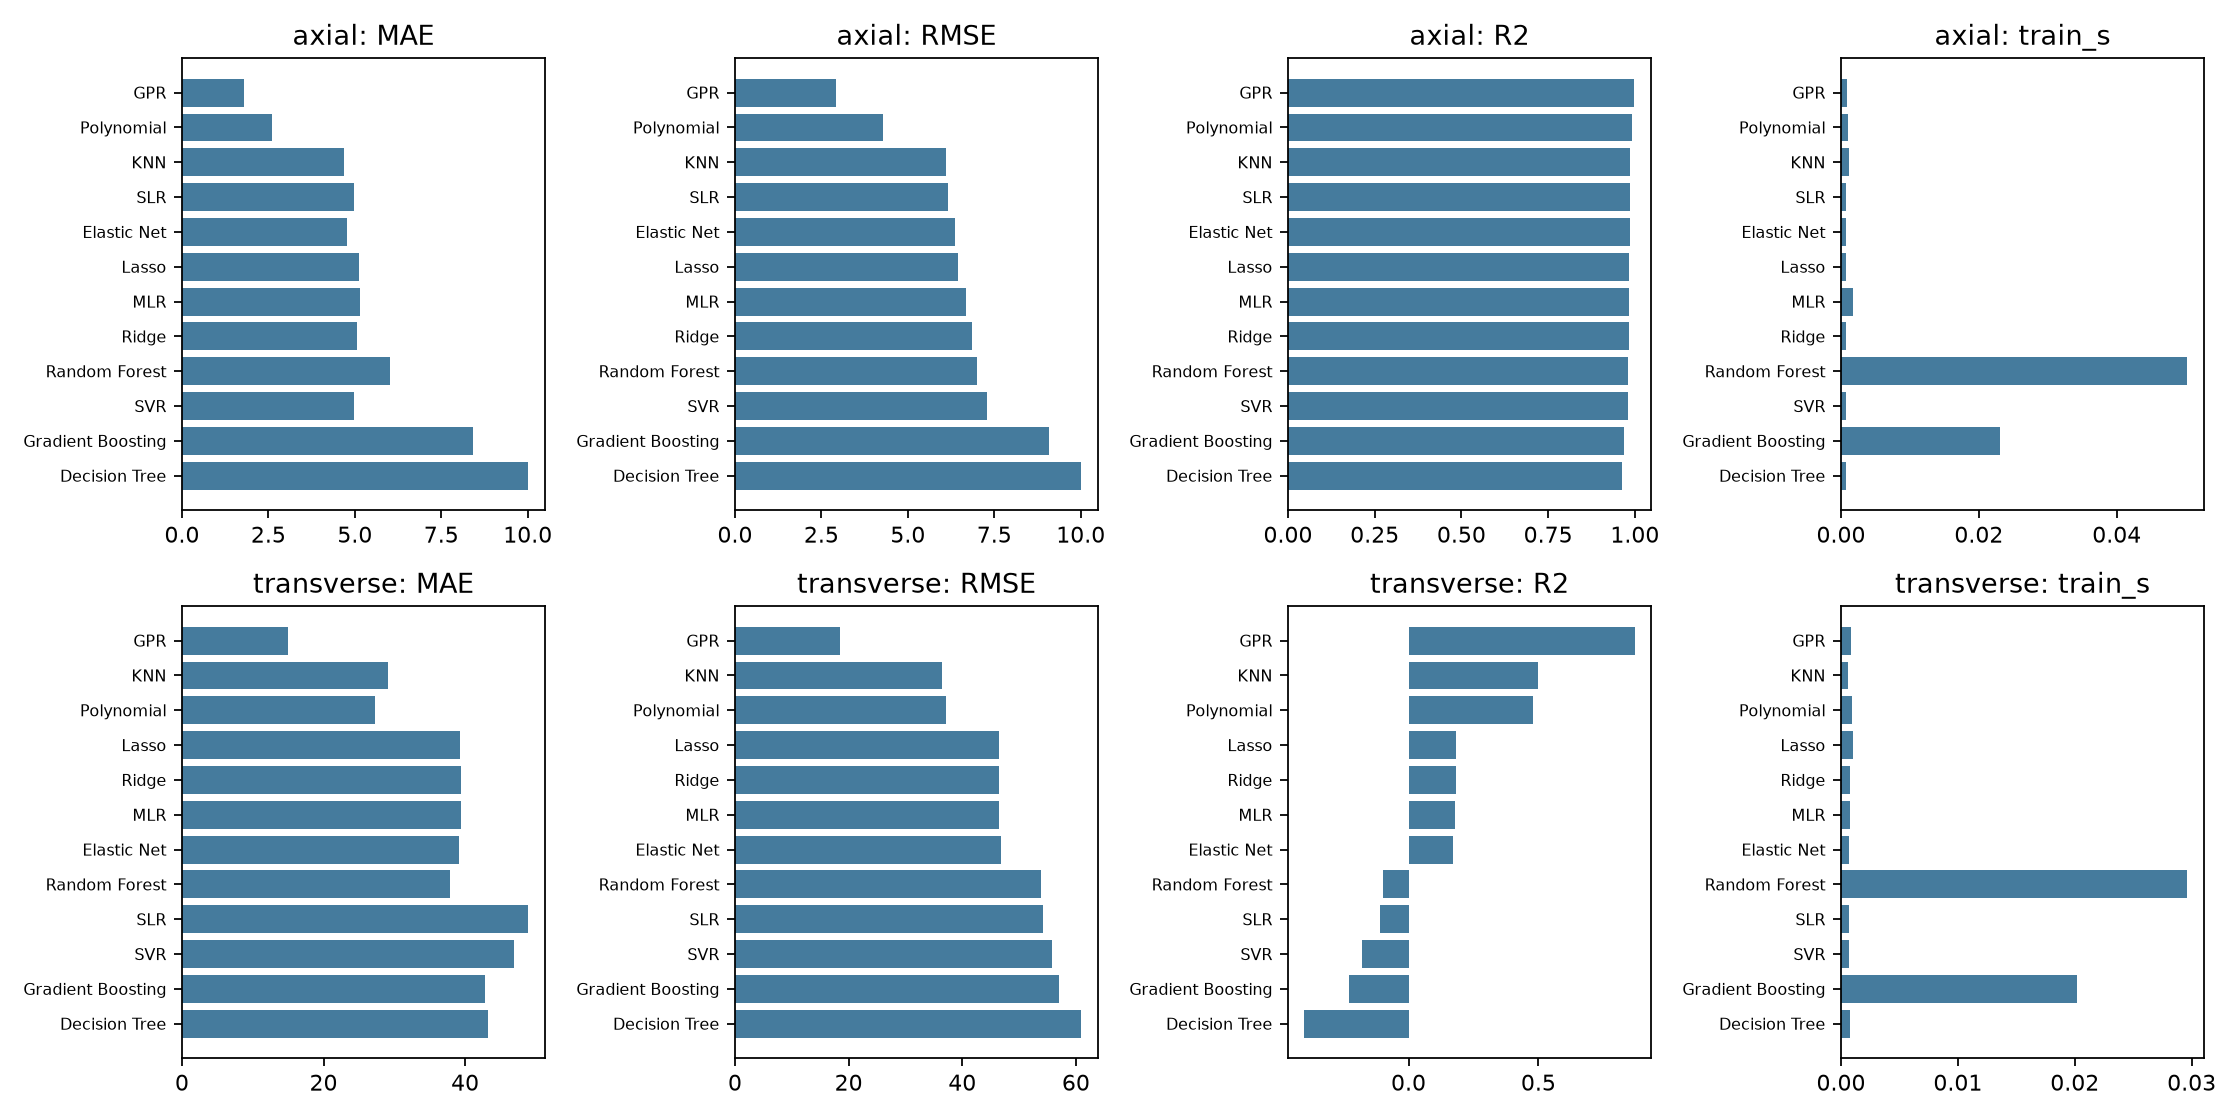

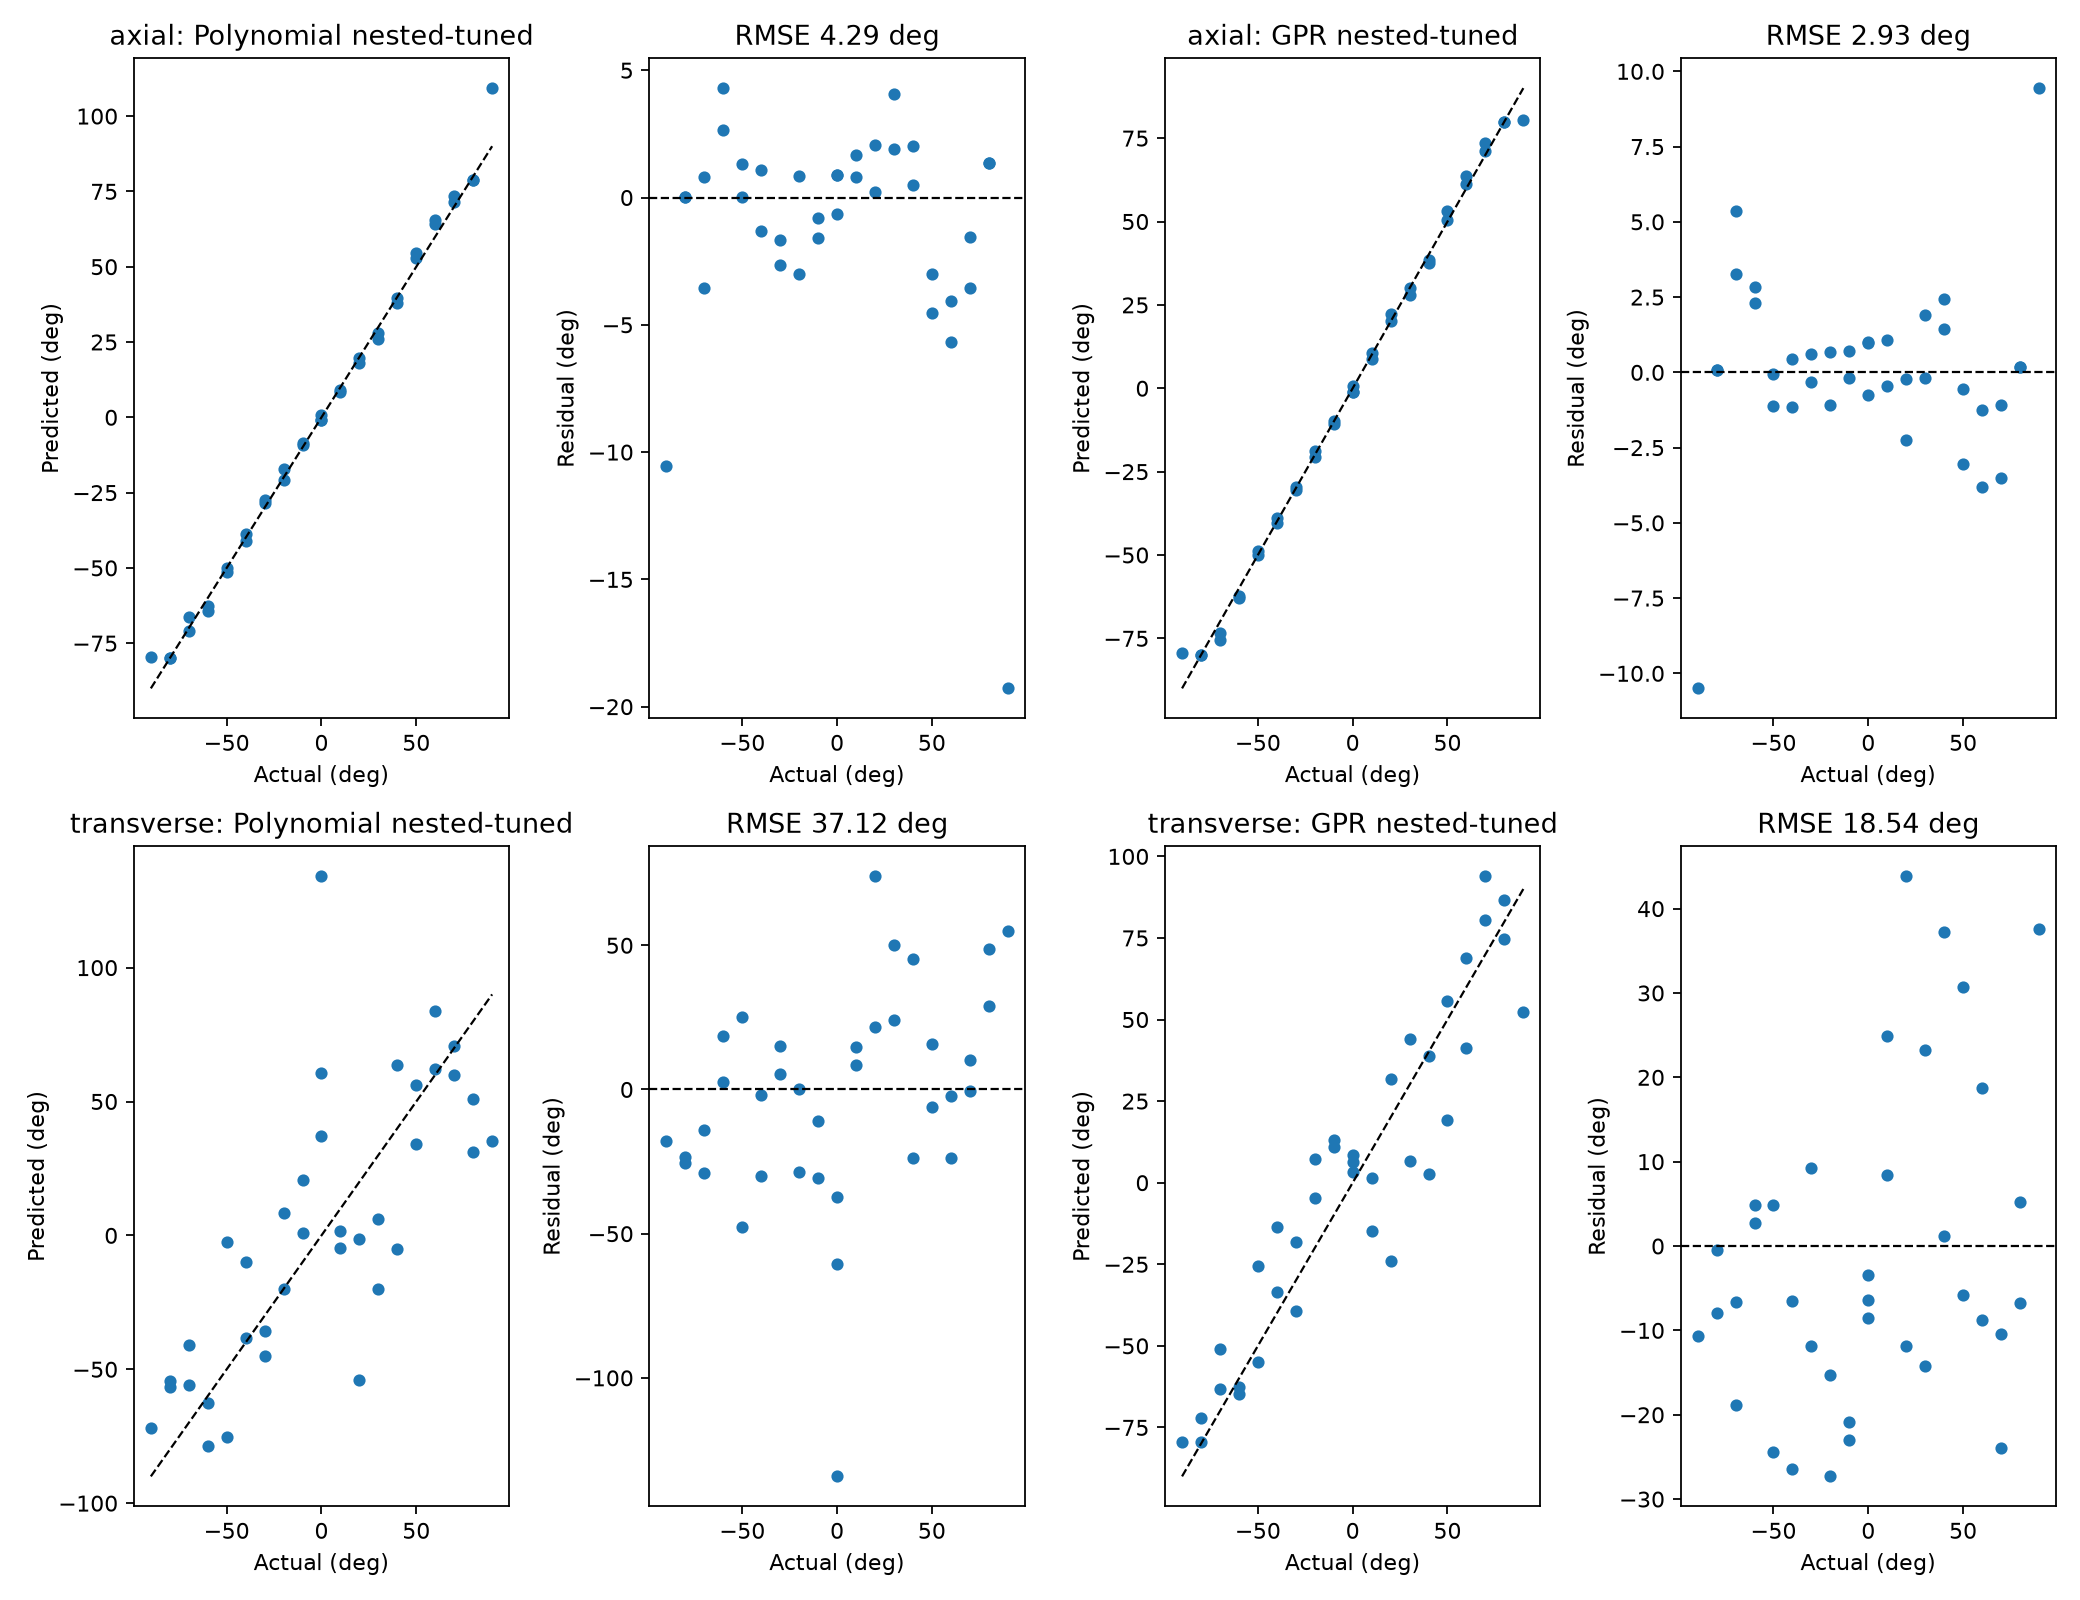

In [7]:
def evaluate(df, axis):
    groups, y = (df.angle.to_numpy(), df.angle.to_numpy())
    outer = GroupKFold(5)
    records, predictions, candidate_folds = ([], [], [])
    for name, config, estimator, feature_options in specs():
        oof = np.full(len(df), np.nan)
        chosen, fit_seconds = ([], [])
        for fold, (train, test) in enumerate(outer.split(df, y, groups), 1):
            inner = GroupKFold(4)
            best = None
            for feature in feature_options:
                x = df[FEATURES[feature]].to_numpy()
                errors = []
                for itrain, ival in inner.split(x[train], y[train], groups[train]):
                    m = model_pipe(estimator)
                    m.fit(x[train][itrain], y[train][itrain])
                    errors.extend(zip(np.repeat(fold, len(ival)), y[train][ival] - m.predict(x[train][ival])))
                rmse = np.sqrt(np.mean([e * e for _, e in errors]))
                if best is None or rmse < best[0]:
                    best = (rmse, feature)
            feature = best[1]
            x = df[FEATURES[feature]].to_numpy()
            model = model_pipe(estimator)
            start = time.perf_counter()
            model.fit(x[train], y[train])
            fit_seconds.append(time.perf_counter() - start)
            oof[test] = model.predict(x[test])
            chosen.append(feature)
            candidate_folds.append({'model': name, 'configuration': config or 'default', 'fold': fold, 'inner_rmse': best[0], 'feature': feature, 'test': test.copy(), 'prediction': oof[test].copy(), 'train_s': fit_seconds[-1]})
            for idx in test:
                predictions.append({'axis': axis, 'model': name, 'configuration': config or 'default', 'fold': fold, 'row': int(idx + 1), 'angle': float(y[idx]), 'prediction': float(oof[idx]), 'residual': float(y[idx] - oof[idx]), 'feature': feature})
        assert np.isfinite(oof).all()
        records.append({'axis': axis, 'model': name, 'configuration': config or 'default', 'feature_mode': Counter(chosen).most_common(1)[0][0], 'feature_folds': ','.join(chosen), 'MAE': mean_absolute_error(y, oof), 'MSE': mean_squared_error(y, oof), 'RMSE': np.sqrt(mean_squared_error(y, oof)), 'R2': r2_score(y, oof), 'train_s': np.mean(fit_seconds)})
    for name in dict.fromkeys((row[0] for row in specs())):
        oof = np.full(len(df), np.nan)
        choices, chosen_features, fit_seconds = ([], [], [])
        for fold in range(1, 6):
            candidates = [r for r in candidate_folds if r['model'] == name and r['fold'] == fold]
            winner = min(candidates, key=lambda r: r['inner_rmse'])
            oof[winner['test']] = winner['prediction']
            choices.append(winner['configuration'])
            chosen_features.append(winner['feature'])
            fit_seconds.append(winner['train_s'])
            for idx in winner['test']:
                predictions.append({'axis': axis, 'model': name, 'configuration': 'nested-tuned', 'fold': fold, 'row': int(idx + 1), 'angle': float(y[idx]), 'prediction': float(oof[idx]), 'residual': float(y[idx] - oof[idx]), 'feature': winner['feature'], 'selected_configuration': winner['configuration']})
        assert np.isfinite(oof).all()
        records.append({'axis': axis, 'model': name, 'configuration': 'nested-tuned', 'feature_mode': Counter(chosen_features).most_common(1)[0][0], 'feature_folds': ','.join(chosen_features), 'configuration_folds': '; '.join(choices), 'MAE': mean_absolute_error(y, oof), 'MSE': mean_squared_error(y, oof), 'RMSE': np.sqrt(mean_squared_error(y, oof)), 'R2': r2_score(y, oof), 'train_s': np.mean(fit_seconds)})
    return (pd.DataFrame(records), pd.DataFrame(predictions))

def plot_results(results, preds):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i, axis in enumerate(('axial', 'transverse')):
        best = results[(results.axis == axis) & (results.configuration == 'nested-tuned')].sort_values('RMSE')
        for j, metric in enumerate(('MAE', 'RMSE', 'R2', 'train_s')):
            ax = axes[i, j]
            ax.barh(best.model, best[metric], color='#457b9d')
            ax.invert_yaxis()
            ax.set_title(f'{axis}: {metric}')
            ax.tick_params(axis='y', labelsize=7)
    fig.tight_layout()
    fig.savefig(OUT / 'model_comparison.png', dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(2, 4, figsize=(13, 10))
    stat = {'SLR', 'MLR', 'Polynomial', 'Ridge', 'Lasso', 'Elastic Net'}
    for i, axis in enumerate(('axial', 'transverse')):
        r = results[(results.axis == axis) & (results.configuration == 'nested-tuned')]
        for k, sub in enumerate((r[r.model.isin(stat)], r[~r.model.isin(stat)])):
            winner = sub.loc[sub.RMSE.idxmin()]
            p = preds[(preds.axis == axis) & (preds.model == winner.model) & (preds.configuration == winner.configuration)]
            a, b = axes[i, k * 2:k * 2 + 2]
            a.scatter(p.angle, p.prediction, s=20)
            a.plot([-90, 90], [-90, 90], 'k--', lw=1)
            a.set(title=f'{axis}: {winner.model} {winner.configuration}', xlabel='Actual (deg)', ylabel='Predicted (deg)')
            b.scatter(p.angle, p.residual, s=20)
            b.axhline(0, color='k', ls='--', lw=1)
            b.set(title=f'RMSE {winner.RMSE:.2f} deg', xlabel='Actual (deg)', ylabel='Residual (deg)')
    fig.tight_layout()
    fig.savefig(OUT / 'predictions_residuals.png', dpi=160)
    plt.close(fig)

result_parts, prediction_parts = [], []
for axis, df in data.items():
    result, prediction = evaluate(df, axis)
    result_parts.append(result)
    prediction_parts.append(prediction)
results = pd.concat(result_parts, ignore_index=True)
predictions = pd.concat(prediction_parts, ignore_index=True)
results.to_csv(OUT / "all_model_results.csv", index=False)
predictions.to_csv(OUT / "all_observation_predictions.csv", index=False)
with open(OUT / "dataset_summary.json", "w") as f:
    json.dump(summaries, f, indent=2)
tuned = predictions[predictions.configuration == "nested-tuned"].copy()
tuned["absolute_error"] = tuned.residual.abs()
tuned.sort_values("absolute_error", ascending=False).groupby(["axis", "model"]).head(5).to_csv(OUT / "worst_angle_errors.csv", index=False)
plot_results(results, predictions)
for axis in data:
    display(results[(results.axis == axis) & (results.configuration == "nested-tuned")].sort_values("RMSE")[["model", "MAE", "MSE", "RMSE", "R2", "train_s", "feature_mode"]])
display(Image(filename=str(OUT / "model_comparison.png")))
display(Image(filename=str(OUT / "predictions_residuals.png")))

## Task 7 — Signed versus absolute tilt
The average wavelength change mostly tracks transverse magnitude, not direction.

In [8]:
def advanced(data):
    df = data['transverse']
    rows = []
    for target in ('signed', 'absolute'):
        y = df.angle.to_numpy() if target == 'signed' else np.abs(df.angle.to_numpy())
        pred = np.full(len(df), np.nan)
        for tr, te in GroupKFold(5).split(df, y, df.angle):
            m = model_pipe(LinearRegression()).fit(df.iloc[tr][['avg']], y[tr])
            pred[te] = m.predict(df.iloc[te][['avg']])
        rows.append({'target': target, 'model': 'linear avg', 'RMSE': np.sqrt(mean_squared_error(y, pred)), 'MAE': mean_absolute_error(y, pred), 'R2': r2_score(y, pred)})
    return pd.DataFrame(rows)

advanced_result = advanced(data)
advanced_result.to_csv(OUT / "advanced_signed_absolute.csv", index=False)
display(advanced_result)

,target,model,RMSE,MAE,R2
0,signed,linear avg,53.293019,45.476797,-0.074493
1,absolute,linear avg,6.748244,5.602420,0.937294


## Result
Axial: Matérn GPR RMSE 2.93°. Signed transverse: tuned GPR RMSE 18.54°. For a simpler axial monitor, the differential linear model is easier to use. The full row-wise predictions are in `results/all_observation_predictions.csv`.